<a href="https://colab.research.google.com/github/kar0karbl/1-TM-Batisova/blob/main/2_laba_TM_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

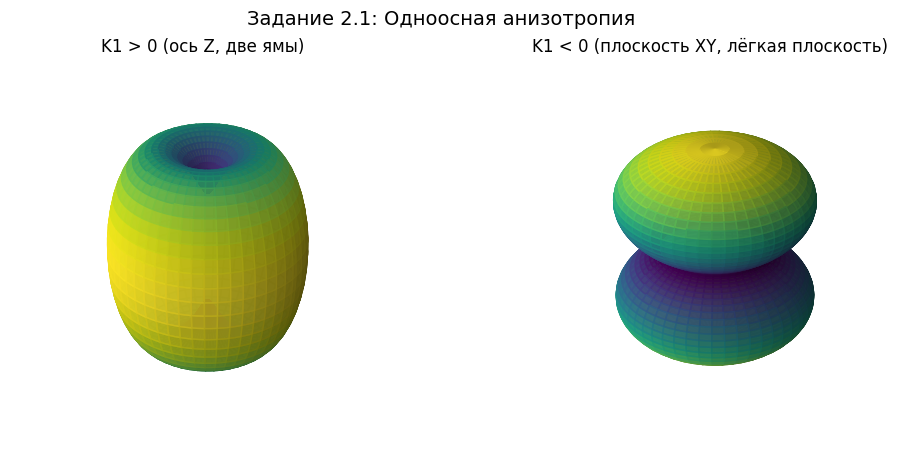

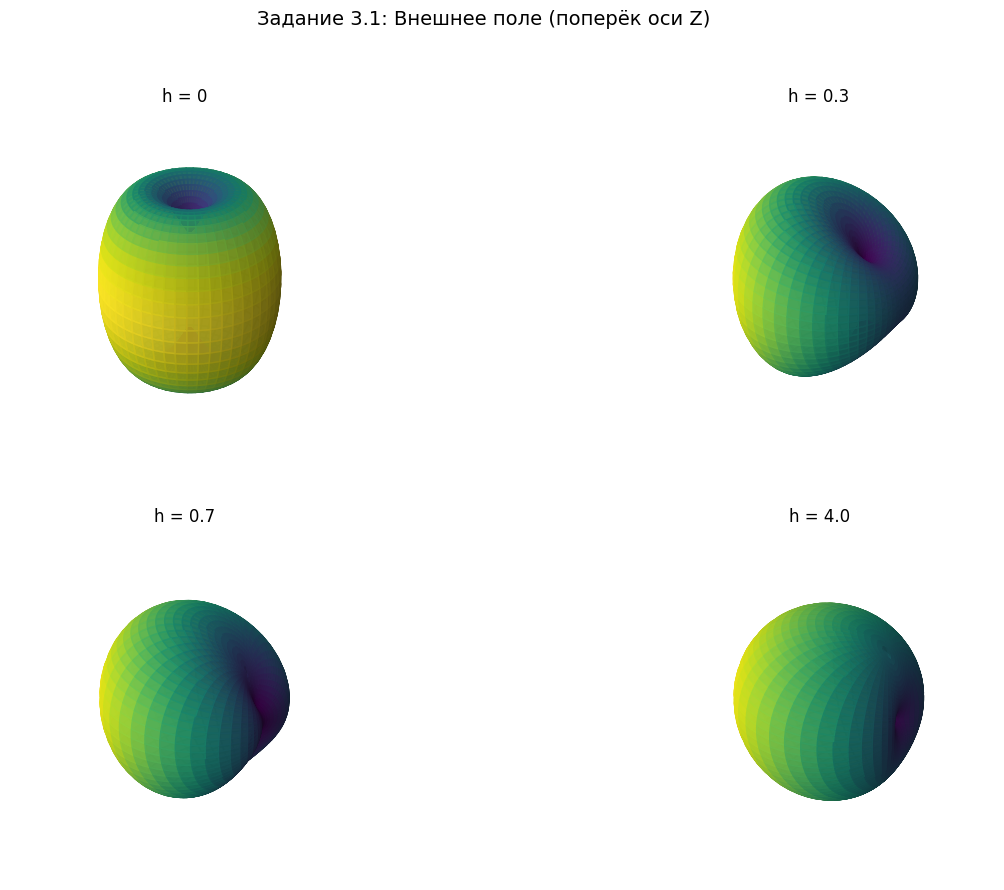

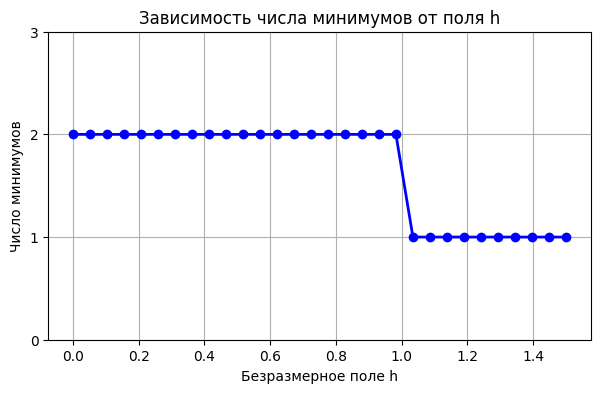

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import minimize

theta = np.linspace(0, np.pi, 100)
phi = np.linspace(0, 2*np.pi, 100)
T, P = np.meshgrid(theta, phi)

ax = np.sin(T) * np.cos(P)
ay = np.sin(T) * np.sin(P)
az = np.cos(T)

def plot_surf(W, title, ax_plot):
    R = (W - np.min(W)) * 3.0 + 1.0
    X = R * np.sin(T) * np.cos(P)
    Y = R * np.sin(T) * np.sin(P)
    Z = R * np.cos(T)

    norm = plt.Normalize(W.min(), W.max())
    colors = cm.viridis(norm(W))

    ax_plot.plot_surface(X, Y, Z, facecolors=colors, rstride=2, cstride=2, alpha=0.9)
    ax_plot.set_title(title, fontsize=12)
    ax_plot.set_box_aspect((1, 1, 1))
    ax_plot.axis('off')

#проверка матрицы Гессе
def count_minima_exact(h):
    if h < 1e-5:
        return 2

    minima = []
    for th0 in np.linspace(0.1, np.pi-0.1, 10):
        for ph0 in np.linspace(0, 2*np.pi, 10, endpoint=False):
            res = minimize(lambda x: np.sin(x[0])**2 - 2*h*np.sin(x[0])*np.cos(x[1]),
                           x0=[th0, ph0], bounds=[(1e-5, np.pi-1e-5), (0, 2*np.pi)], method='L-BFGS-B')

            if res.success:
                th, ph = res.x

                #проверка градиента
                grad_th = 2*np.sin(th)*np.cos(th) - 2*h*np.cos(th)*np.cos(ph)
                grad_ph = 2*h*np.sin(th)*np.sin(ph)
                if np.abs(grad_th) > 1e-4 or np.abs(grad_ph) > 1e-4:
                    continue

                #проверка матрицы Гессе
                E_thth = 2*np.cos(2*th) + 2*h*np.sin(th)*np.cos(ph)
                E_phph = 2*h*np.sin(th)*np.cos(ph)
                E_thph = 2*h*np.cos(th)*np.sin(ph)
                det = E_thth * E_phph - E_thph**2

                if E_thth > 1e-5 and det > 1e-5:
                    x = np.sin(th)*np.cos(ph)
                    y = np.sin(th)*np.sin(ph)
                    z = np.cos(th)

                    dup = False
                    for mx, my, mz in minima:
                        if (x-mx)**2 + (y-my)**2 + (z-mz)**2 < 0.01:
                            dup = True
                            break
                    if not dup:
                        minima.append((x, y, z))
    return len(minima)

#2.1
fig1 = plt.figure(figsize=(12, 5))
fig1.suptitle("Задание 2.1: Одноосная анизотропия", fontsize=14)

w_uni_pos = np.sin(T)**2
plot_surf(w_uni_pos, "K1 > 0 (ось Z, две ямы)", fig1.add_subplot(121, projection='3d'))

w_uni_neg = -np.sin(T)**2
plot_surf(w_uni_neg, "K1 < 0 (плоскость XY, лёгкая плоскость)", fig1.add_subplot(122, projection='3d'))
plt.show()

#3.1
fig3 = plt.figure(figsize=(15, 10))
fig3.suptitle("Задание 3.1: Внешнее поле (поперёк оси Z)", fontsize=14)

h_vals = [0, 0.3, 0.7, 4.0]
for i, h in enumerate(h_vals):
    w_total = w_uni_pos - 2 * h * ax
    plot_surf(w_total, f"h = {h}", fig3.add_subplot(2, 2, i+1, projection='3d'))
plt.show()

#3.4
h_range = np.linspace(0, 1.5, 30)
min_counts = [count_minima_exact(h) for h in h_range]

plt.figure(figsize=(7, 4))
plt.plot(h_range, min_counts, 'bo-', lw=2)
plt.title("Зависимость числа минимумов от поля h")
plt.xlabel("Безразмерное поле h")
plt.ylabel("Число минимумов")
plt.yticks([0, 1, 2, 3])
plt.grid(True)
plt.show()